# The heat equation

This tutorial follows the chapter on time dependent problems (the diffusion equation) in the
[FEniCSx tutorial](https://jsdokken.com/dolfinx-tutorial/).
We solve

$$ \partial_t u - \Delta u = f \quad \text{in } \Omega, \qquad u = u_D \quad \text{on } \partial\Omega, \qquad u(0) = u_0 , $$

with the implicit Euler method.  With $u^n \approx u(t_n)$ and step $\Delta t$ each step
asks for $u^{n+1}$ with

$$ \int_\Omega u^{n+1} v + \Delta t\, \nabla u^{n+1}\cdot\nabla v \, dx = \int_\Omega (u^n + \Delta t\, f^{n+1})\, v \, dx . $$

The system matrix does not change from step to step, so it is assembled and factorised
only once.  Two examples: a manufactured solution with a time dependent boundary value,
and the diffusion of a Gaussian hill.

## Part 1: manufactured solution

Take $u_e = 1 + x^2 + \alpha y^2 + \beta t$ with $\alpha = 3$, $\beta = 1.2$, which
gives $f = \beta - 2 - 2\alpha$ and a boundary value $u_D = u_e$ that depends on $t$.
The time $t$ is a `Constant`: when we `assign` a new value, every form and boundary
condition that contains it sees the update, nothing has to be rebuilt.

In [1]:
from ngsufl import *

mesh = UnitSquareMesh(10, 10)
V = FunctionSpace(mesh, "Lagrange", 2)
x = SpatialCoordinate(mesh)

alpha, beta = 3.0, 1.2
t = Constant(0.0)
u_e = 1 + x[0]**2 + alpha * x[1]**2 + beta * t
f = Constant(beta - 2 - 2 * alpha)

The time stepping form is written once as a residual in the unknown `u`; `lhs` and
`rhs` split it into the bilinear and the linear part.  `u_n` is the solution of the
previous step.  We pass `constant_jacobian=True` to tell the solver that the matrix is
the same in every step.

In [2]:
dt = 0.1
u, v = TrialFunction(V), TestFunction(V)
u_n = Function(V, name="u_n").interpolate(u_e)

F = u * v * dx + dt * inner(grad(u), grad(v)) * dx - (u_n + dt * f) * v * dx
a, L = lhs(F), rhs(F)

uh = Function(V, name="u")
bc = DirichletBC(V, u_e, "on_boundary")
problem = LinearVariationalProblem(a, L, uh, bc, constant_jacobian=True)
solver = LinearVariationalSolver(problem)

In [3]:
for n in range(10):
    t.assign(t.value + dt)
    solver.solve()
    u_n.assign(uh)

print(f"t = {t.value:.2f}")
print("L2 error at final time:", errornorm(u_e, uh))

t = 1.00
L2 error at final time: 3.880739817399947e-15


The exact solution is quadratic in space and linear in time, so both the spatial
discretisation (degree 2) and the implicit Euler method reproduce it exactly, and the
error is at round-off level.  This is a useful test of the time stepping code, since
any slip in the boundary update or in the right hand side shows up immediately.

## Part 2: diffusion of a Gaussian hill

Now on the square $(-2, 2)^2$ with the initial hill $u_0 = \exp(-a (x^2 + y^2))$,
$a = 5$, and $f = 0$, $u_D = 0$.  Since the hill is far from the boundary, the solution
is close to the one on the whole plane,

$$ u(x, y, t) = \frac{1}{1 + 4at}\, \exp\!\Big(-\frac{a\,(x^2 + y^2)}{1 + 4at}\Big) , $$

which we use as a reference.  `RectangleMesh` takes an `origin`.

In [4]:
mesh = RectangleMesh(40, 40, 4.0, 4.0, origin=(-2.0, -2.0))
V = FunctionSpace(mesh, "Lagrange", 2)
x = SpatialCoordinate(mesh)

a_hill, dt, T = 5.0, 0.005, 0.1
hill = lambda t: exp(-a_hill * (x[0]**2 + x[1]**2) / (1 + 4 * a_hill * t)) / (1 + 4 * a_hill * t)

u_n = Function(V, name="u_n").interpolate(hill(0.0))
u, v = TrialFunction(V), TestFunction(V)
F = u * v * dx + dt * inner(grad(u), grad(v)) * dx - u_n * v * dx
uh = Function(V, name="u")
solver = LinearVariationalSolver(
    LinearVariationalProblem(lhs(F), rhs(F), uh, DirichletBC(V, 0.0, "on_boundary"), constant_jacobian=True)
)

We keep a few snapshots while stepping.

In [5]:
import numpy as np
import matplotlib.pyplot as plt

nsteps = round(T / dt)
snap_steps = {0: u_n.copy(), nsteps // 4: None, nsteps // 2: None, nsteps: None}

for n in range(1, nsteps + 1):
    solver.solve()
    u_n.assign(uh)
    if n in snap_steps:
        snap_steps[n] = uh.copy()

print("steps:", nsteps)

steps: 20


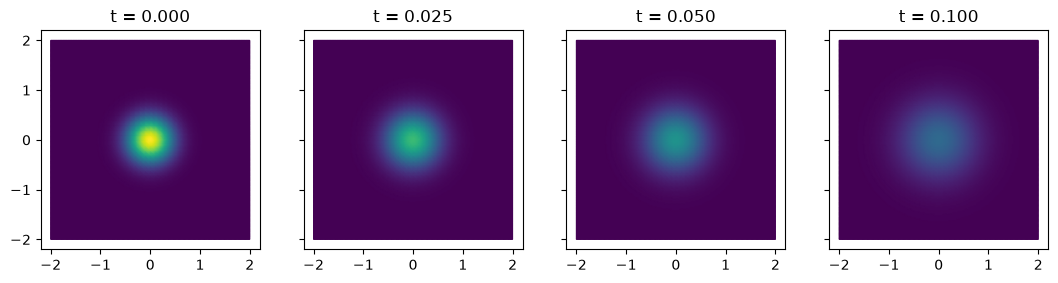

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2), sharey=True)
for ax, (n, s) in zip(axes, snap_steps.items()):
    plot(s, ax=ax, colorbar=False, vmin=0, vmax=1)
    ax.set_title(f"t = {n * dt:.3f}")
    ax.set_aspect("equal")

## Check against the exact solution

The error at the final time is dominated by the first order error of implicit Euler,
so it should halve when $\Delta t$ does.  We wrap the time loop in a function and
repeat it for smaller steps.

In [7]:
print("L2 error vs plane solution at T:", errornorm(hill(T), uh))

L2 error vs plane solution at T: 0.004342142124864868


In [8]:
def final_error(dt):
    u_n = Function(V).interpolate(hill(0.0))
    u, v = TrialFunction(V), TestFunction(V)
    F = u * v * dx + dt * inner(grad(u), grad(v)) * dx - u_n * v * dx
    uh = Function(V)
    bc = DirichletBC(V, 0.0, "on_boundary")
    solver = LinearVariationalSolver(LinearVariationalProblem(lhs(F), rhs(F), uh, bc, constant_jacobian=True))
    for n in range(round(T / dt)):
        solver.solve()
        u_n.assign(uh)
    return errornorm(hill(T), uh)


errs = [final_error(dt) for dt in (0.01, 0.005, 0.0025)]
print("errors:", errs)
print("observed rates:", [round(float(np.log2(errs[i] / errs[i + 1])), 2) for i in range(2)])

errors: [0.008557644381294046, 0.004342142124864868, 0.0021931655291462385]
observed rates: [0.98, 0.99]
